#### Precipitation Hovmöller Diagram
Hourly precipitation averaged over a latitude band, plotted vs. longitude and time, to track propagating precipitation systems or a diurnal cycle across the run.

**Data**: SouthAmerica 240-48km variable-resolution tutorial run, hourly `diag.*.nc` output (same files used in `plot_mpas_windRose.ipynb` / `plot_mpas_spd_ts.ipynb`).

Ming Ge Nov. 2026

In [1]:
import glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from mpas_utils import mpas_lonlat_deg

#### Load mesh and list hourly files

In [2]:
data_dir = '/glade/campaign/mmm/c3we/mingge/MPAS_PROJ/mpas_tutorial/240-48km_variable/'

ds_i = xr.open_dataset(data_dir + 'SouthAmerica.init.nc')
lonCell, latCell = mpas_lonlat_deg(ds_i['lonCell'].values, ds_i['latCell'].values)

diag_files = sorted(glob.glob(data_dir + 'diag.2014-09-1*.nc'))
print(f'{len(diag_files)} hourly diag files found')

41 hourly diag files found


#### Bin accumulated-precip differences into a longitude x time array over a latitude band

In [3]:
lat_band = (-25, -15)   # crosses the ~48km-resolution South America nest
lon_bounds = (-80, -55)
lon_bins = np.arange(lon_bounds[0], lon_bounds[1], 0.5)

in_band = (latCell >= lat_band[0]) & (latCell <= lat_band[1])
lon_band = lonCell[in_band]
lon_idx = np.digitize(lon_band, lon_bins)  # 1..len(lon_bins), per-cell lon-bin index

times, rows = [], []
rain_prev = None

for f in diag_files:
    with xr.open_dataset(f) as ds:
        t = pd.to_datetime(ds['xtime'].values[0].decode().strip()[:19], format='%Y-%m-%d_%H:%M:%S')
        rain_total = (ds['rainc'] + ds['rainnc']).isel(Time=0).values  # mm, accumulated since run start

    if rain_prev is not None:
        hourly = (rain_total - rain_prev)[in_band]
        profile = np.array([
            hourly[lon_idx == i].mean() if np.any(lon_idx == i) else np.nan
            for i in range(1, len(lon_bins) + 1)
        ])
        rows.append(profile)
        times.append(t)

    rain_prev = rain_total

hovmoller = np.array(rows)

#### Plot

Text(0.5, 1.0, 'Hourly precipitation Hovmöller, -25 to -15 deg latitude band')

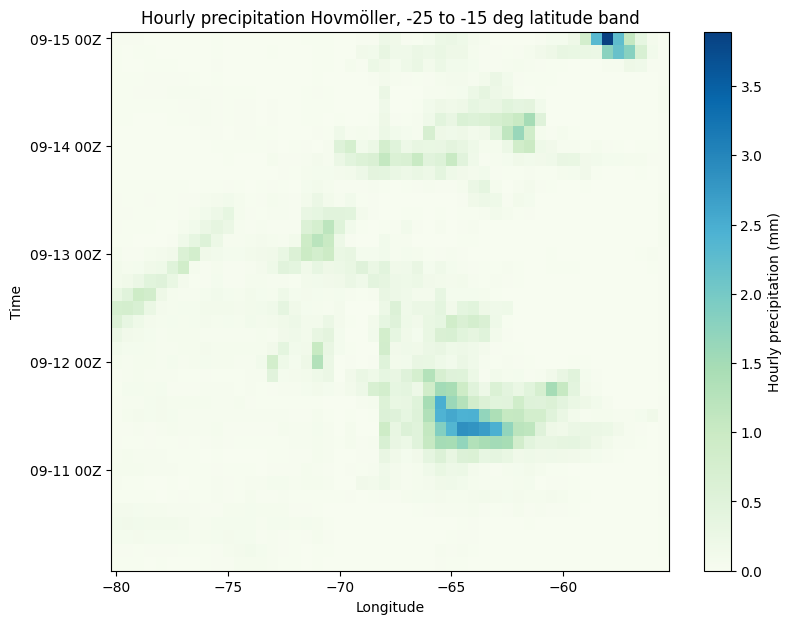

In [4]:
fig, ax = plt.subplots(figsize=(9, 7))
mm = ax.pcolormesh(lon_bins, times, hovmoller, cmap='GnBu', shading='nearest')
plt.colorbar(mm, ax=ax, label='Hourly precipitation (mm)')

ax.yaxis_date()
ax.yaxis.set_major_formatter(mdates.DateFormatter('%m-%d %HZ'))
ax.set_xlabel('Longitude')
ax.set_ylabel('Time')
ax.set_title(f'Hourly precipitation Hovmöller, {lat_band[0]} to {lat_band[1]} deg latitude band')